In [4]:
# desenvolver media ponderada

In [15]:
import statistics as sts
import pandas as pd
from scipy.stats import trim_mean, iqr, median_abs_deviation
import numpy as np

In [29]:
def resumo_estatistico_media(df, proportiontocut= 0.05, axis=0, center= np.median, scale=1.0, nan_policy='omit', interpolation='linear'):
    media = df.mean()
    mediana = df.median()
    variancia = df.var()
    desvio_padrão = df.std()
    media_abs_desvio = df.mad()
    df = df.select_dtypes(exclude=['object'])
    df = df.fillna(value=0)
    colunas = df.columns 
    media_truncada = []
    desvio_abs_mediana = []
    iqr_list = []
    for columns in df.columns:
        df1 = np.array(df[columns])
        media_trunc = trim_mean(df1, proportiontocut= proportiontocut, axis=axis) #parametro da função
        desv_abs_mediana = median_abs_deviation(df1, axis=axis, center=center, scale=scale, nan_policy= nan_policy)
        iqr_value = iqr(df1, axis=None, rng=(25, 75), scale=1.0, nan_policy= nan_policy, interpolation= interpolation, keepdims=False)
        media_truncada.append(media_trunc)
        desvio_abs_mediana.append(desv_abs_mediana)
        iqr_list.append(iqr_value)
    medias_truncadas_df = pd.DataFrame(media_truncada, index=colunas, columns=['media_truncada'])
    desvio_abs_mediana_df = pd.DataFrame(desvio_abs_mediana, index=colunas, columns=['desvio_abs_mediana'])
    iqr_df = pd.DataFrame(iqr_list, index=colunas, columns=['iqr'])
    mediadf =pd.DataFrame(media, columns=['media'])
    medianadf =pd.DataFrame(mediana, columns=['mediana'])
    variancia_df = pd.DataFrame(variancia, columns=['variancia'])
    desvio_padrão_df = pd.DataFrame(desvio_padrão, columns=['desvio_padrão'])
    media_abs_desvio_df = pd.DataFrame(media_abs_desvio, columns=['media_abs_desvio'])
    resumo = mediadf.join(medias_truncadas_df)
    resumo = resumo.join(medianadf)
    resumo = resumo.join(variancia_df)
    resumo = resumo.join(desvio_padrão_df)
    resumo = resumo.join(media_abs_desvio_df)
    resumo = resumo.join(desvio_abs_mediana_df)
    resumo = resumo.join(iqr_df)
    return resumo

In [30]:
df = pd.read_excel('C:/Users/Nivea Helena/Documents/developer/ciencia de dados/projetos_ds/Data_cleaning/Earlwood_Air_Data_17_18.xls/Earlwood_Air_Data_17_18.xls')

In [31]:
df = df.rename(columns={'Date': 'Date', 'Time': 'Time', 'EARLWOOD WDR 1h average [°]': 'WDR',
       'EARLWOOD TEMP 1h average [°C]': 'TEMP', 'EARLWOOD WSP 1h average [m/s]': 'WSP',
       'EARLWOOD NO 1h average [pphm]': 'NO', 'EARLWOOD NO2 1h average [pphm]': 'NO2',
       'EARLWOOD CO 1h average [ppm]': 'CO', 'EARLWOOD OZONE 1h average [pphm]': 'OZONE',
       'EARLWOOD OZONE 4h rolling average [pphm]': 'OZONE_4',
       'EARLWOOD PM10 1h average [µg/m³]': 'PM10', 'EARLWOOD PM2.5 1h average [µg/m³]': 'PM2.5',
       'EARLWOOD HUMID 1h average [%]': 'HUMID', 'EARLWOOD SD1 1h average [°]': 'SD1',
       'EARLWOOD CO 8h rolling average [ppm]': 'CO_8'})

<AxesSubplot:>

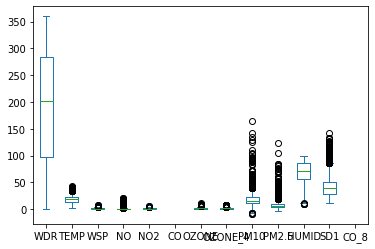

In [32]:
df.plot.box()

In [33]:
resumo_estatistico_media(df, proportiontocut= 0.05, axis=0)

C:\Users\Nivea Helena\AppData\Local\Temp\ipykernel_33964\903682855.py:2: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  media = df.mean()
C:\Users\Nivea Helena\AppData\Local\Temp\ipykernel_33964\903682855.py:3: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  mediana = df.median()
C:\Users\Nivea Helena\AppData\Local\Temp\ipykernel_33964\903682855.py:4: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  variancia = df.var()
C:\Users\Nivea Helena\AppData\Local\Temp\ipykernel_33964\903682855.py:5:

,media,media_truncada,mediana,variancia,desvio_padrão,media_abs_desvio,desvio_abs_mediana,iqr
WDR,190.913518,191.806236,201.40,10233.007486,101.158329,89.132499,87.65,185.925
TEMP,18.218411,18.150139,18.60,34.714299,5.891884,4.756928,4.00,8.300
WSP,1.254709,1.181900,1.10,0.838468,0.915679,0.716103,0.60,1.300
NO,1.288005,0.782241,0.20,6.917378,2.630091,1.677644,0.10,0.900
NO2,1.080325,0.967202,0.90,0.634192,0.796362,0.659133,0.50,1.200
CO,NaN,0.000000,NaN,NaN,NaN,NaN,0.00,0.000
OZONE,1.633215,1.393069,1.70,1.482969,1.217772,0.976506,1.10,2.200
OZONE_4,1.609506,1.439021,1.60,1.289873,1.135726,0.907052,0.90,1.900
PM10,18.038783,17.143157,16.10,108.675655,10.424762,7.466202,5.60,11.600
PM2.5,7.295264,6.483279,5.90,44.475482,6.668994,4.274862,2.90,6.000


In [11]:
#desvio - diferença entre o valor observado e a media
#variancia - distancia entre o valor observado e a media
#desvio Padrão - indica o quanto os valores observados estão uniformes ou não. Ou seja, quanto maior o DP, ais o conjunto está disperso ok
#desvio medio absoluto - media dos desvios -  é um erro estatístico que calcula a média de distância entre cada par de pontos de dados reais e ajustados. ok
#desvio medio absoluto da mediana - não é influenciado por outliers, 
#intervalo - 
#percentis - 
#intervalos interquartis - 

In [14]:
#desvio Padrão
df.std()

C:\Users\Nivea Helena\AppData\Local\Temp\ipykernel_33964\2023381258.py:2: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  df.std()


WDR        101.158329
TEMP         5.891884
WSP          0.915679
NO           2.630091
NO2          0.796362
CO                NaN
OZONE        1.217772
OZONE_4      1.135726
PM10        10.424762
PM2.5        6.668994
HUMID       19.597350
SD1         19.879278
CO_8              NaN
dtype: float64

In [113]:
#desvio médio absoluto
df.mad()

WDR        89.132499
TEMP        4.756928
WSP         0.716103
NO          1.677644
NO2         0.659133
CO               NaN
OZONE       0.976506
OZONE_4     0.907052
PM10        7.466202
PM2.5       4.274862
HUMID      16.214773
SD1        15.282914
CO_8             NaN
dtype: float64